# E95: Does "reuses token identity" say more than "the state needs the input token"?

**The answer.** Removing token identity's directions costs a hand-built key reader about three quarters of its gain, more than it costs any fine-tuned state. So a loss under this removal is not shown to mean more than needing the input token. The copy map does lose more than the random map on a second, independent pair of tables, a real difference of degree whose control barely passed. Its cause is unmeasured. A circuit built from old parts would read the same.

*Status: provisional, no independent check.*


## What we were trying to test

The original model is fine-tuned on a marker task: a key token sits at one position, and the model must give that key's answer. On the copy map the answer is the key itself. On the random map the answer is an arbitrary other token.

The measurement removes a set of directions from the residual at block 1's output, at the key's position only. Those directions, the basis, are where token identity lives: where the original model's residuals differ between keys on natural text. Random removals of the same rank, matched to about the same variance, are the null. There are 20 of them, and the same 20 are read on every row.

The number read is the **share of gain lost**: the state's mean log-odds drop under the removal, minus the original model's drop, over the state's log-odds gain. At 0 the removal costs the state no more than it costs the original model. At 1 the whole gain is gone.

An earlier experiment found that the copy map loses more than the random map here, on one pair of tables. Its independent check raised a problem. The key sits nowhere earlier in the window, so anything downstream that needs the key must read it through this residual. The hand-built control in that experiment reads its key upstream of the removal, so it says nothing about this.

This run adds two things and trains nothing.

```
embedding → block 0 → block 1 → [removal, at the key's position] → block 2 → block 3 → answer
                         ↑                                            ↑
                  block-1 hand write                          block-2 hand write
               upstream, spared by placement             reads its key through the removal
```

- **A hand write at block 2.** One weight matrix, solved so that 32 key activations map to their answers, scaled to the state's gain. It is built by hand, so it is no old mechanism, and it does nothing but read the key and write the answer. The alternative it tests: any reader of the key loses this much under this removal.
- **A replicate pair of tables.** Two fine-tuned maps on 32 keys that share none with the first pair, two seeds each. The alternative it tests: the copy-over-random difference is one table pair's accident.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/token_identity/figures")


## What we expected, and why

**The write.** We leaned towards the write losing as much as the states or more, and towards the plain outcome "token needed, no more". A linear reader of the key has to read where the keys' means differ, and that is the basis. Against that lean stood the extra loss of copy over random, which a need both maps share does not explain. A lean is not a bar.

**The replicate.** We leaned towards copy above the filed band and random under it, on every pair of seeds. The random map was the live risk, since it sat close to its own reference on the first pair.

**The controls.** The original model must lose more under the basis than under the draws. Doing nothing must read "no gain". The first pair's numbers must reproduce to within 0.001, or the job stops.


## What we observed

### Does a key reader downstream of the removal lose as much as the states?


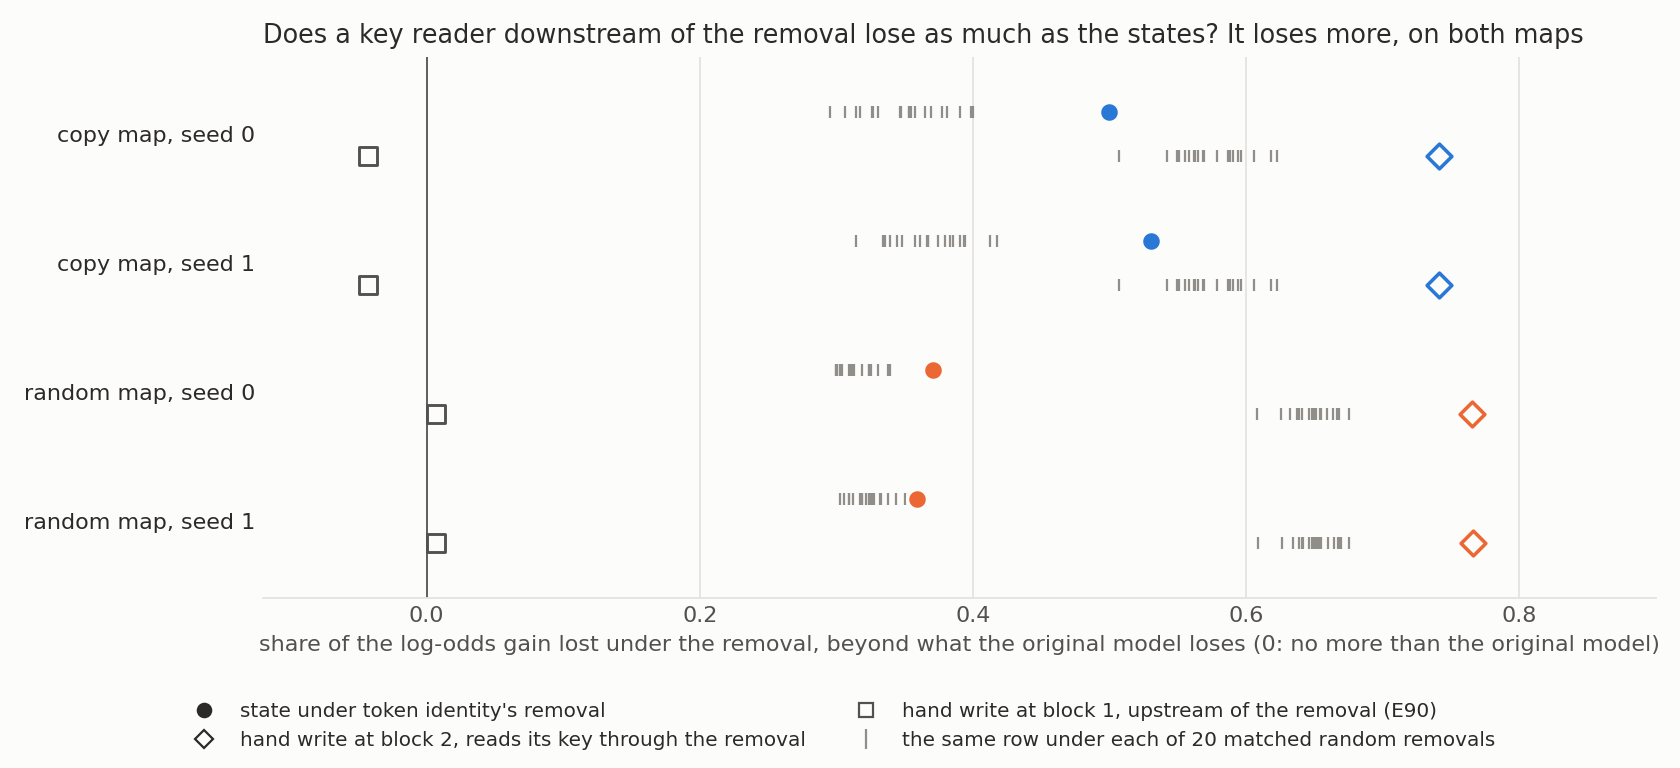

In [2]:
display(Image(FIG / "read1_shares.png", width=900))


**Reading it.** It loses more, on both maps. The diamonds are the block-2 write, at 0.74 on copy and 0.77 on random. They sit past all 20 of their own random removals. The dots are the states: copy at about 0.5, random at about 0.36. The squares are the same write one block earlier, which loses about nothing, so placement alone moves this number by about three quarters of the gain. So the removal does hit a mechanism that needs nothing but the token. The caveat is the write itself: it is a pseudo-inverse on 32 means, and it may be more fragile than a trained circuit.


### Is the states' shortfall against the write more than matched directions give?


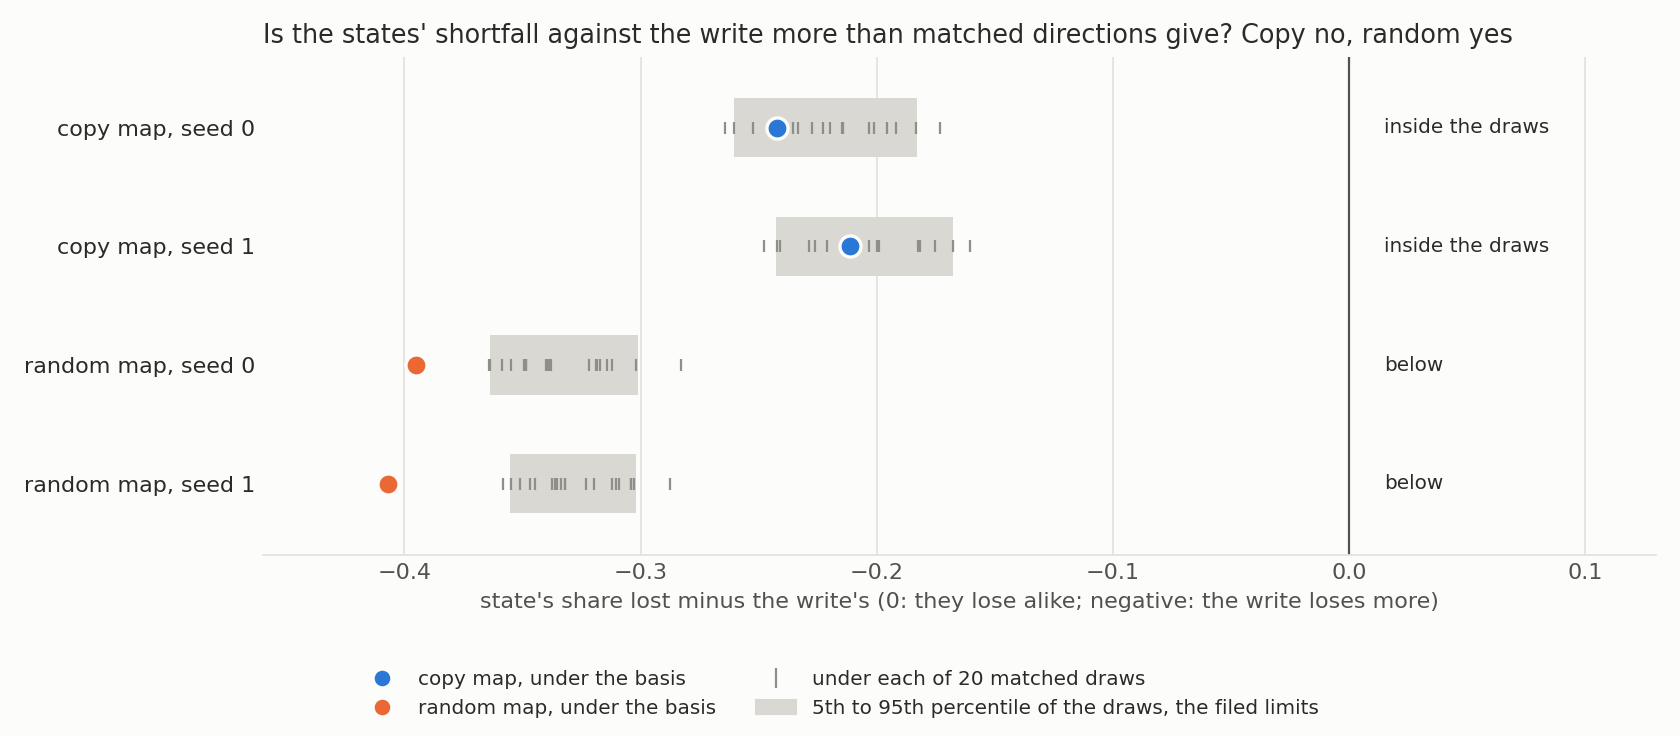

In [3]:
display(Image(FIG / "read1_gaps.png", width=900))


**Reading it.** For copy no, for random yes, and the filed outcome is "no call". Each dot is the state's share minus the write's, so a negative value means the write loses more. Copy's gaps sit inside what the random removals give. Random's sit below the lower limit. Tested pair by pair, the copy-over-random difference in this gap clears all the draws on two of four seed pairs, so it is not a separation.

The filed sentence for this outcome reads "a state loses more than the write, by about what matched directions give". On these numbers that is backwards: every state loses less than the write. The rule tests whether the gap lies inside the draws and never reads its sign, and the sentence was written with a positive gap in mind. The filing stands unedited, and "no call" is the outcome. The accurate sentence is that copy loses less than the write, by about what matched directions give.


### On keys unshared with the first pair, does copy clear the band and random stay under it?


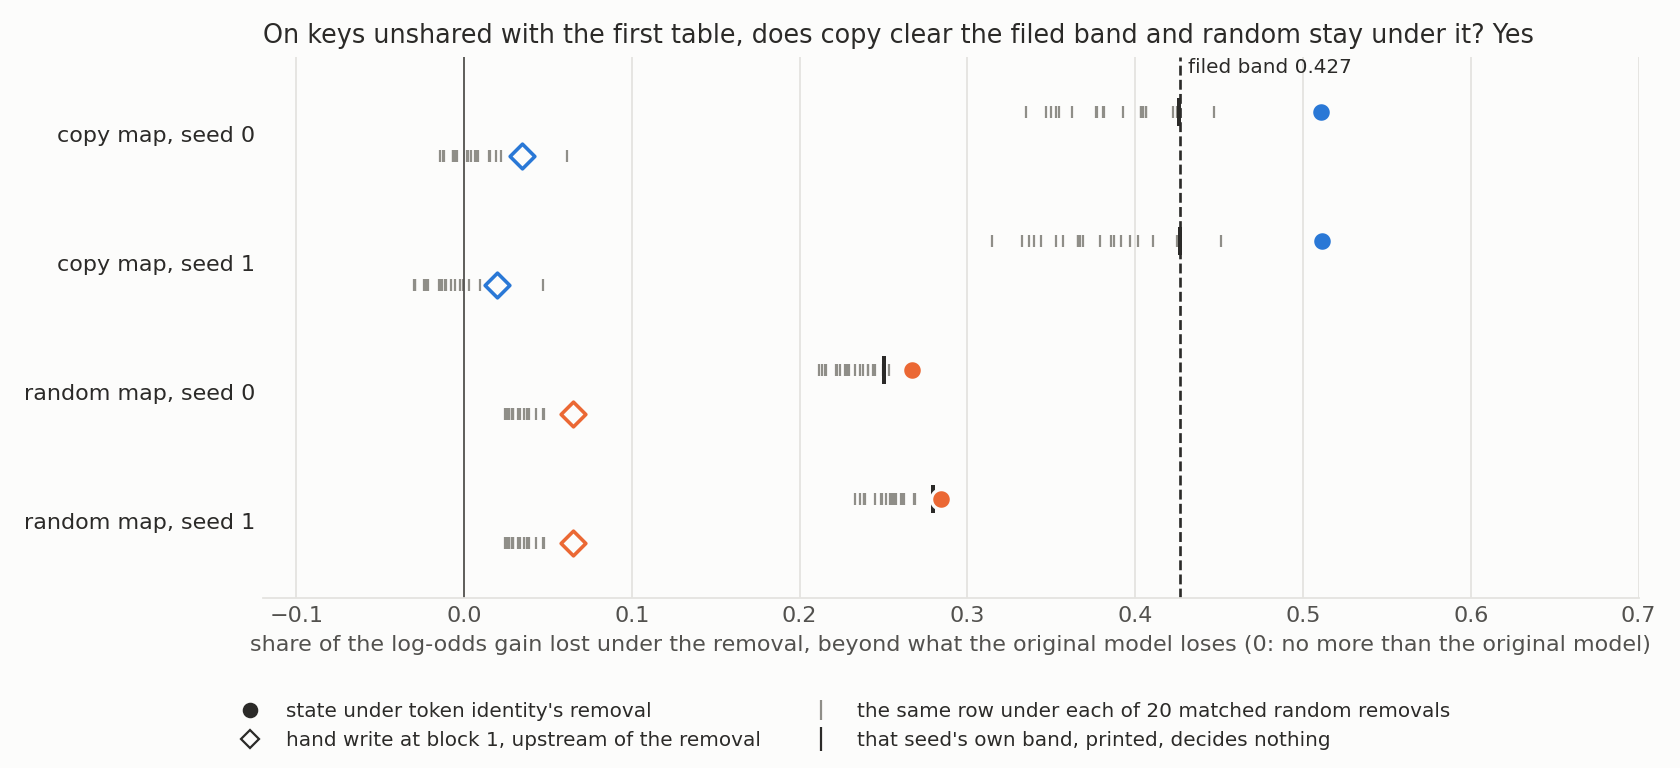

In [4]:
display(Image(FIG / "read2_shares.png", width=900))


**Reading it.** Yes, by the filed rule. Copy reads 0.51 on both seeds, over the filed band of 0.43, and the filed verdict is "reuses C". Random reads 0.27 and 0.28, under it, and the filed verdict is "does not reach the states". The band is the largest over all states and writes, so copy sets it for random as well. Each seed's own band tells random differently: both seeds sit just above their own, by 0.017 and 0.005, and past all 20 of their draws. "Does not reach" reads wrongly in plain words, since this answer must reach its key through this residual.

Three things hold this result back. The original model's control passed by very little, 2.858 against a band of 2.842, and one of the 20 draws exceeded it. On a normal fit to those draws, about half of fresh sets of 20 would have failed that control, and the filed outcome would then be "no call". The draws also hold only 0.89 of the basis's variance on the task windows, so the filing says copy's "above" is not cleared of size there. Scaling the band up to a full match gives roughly 0.48, still under 0.51, and that is an estimate.


### Does copy lose more than random beyond what the same draw gives?


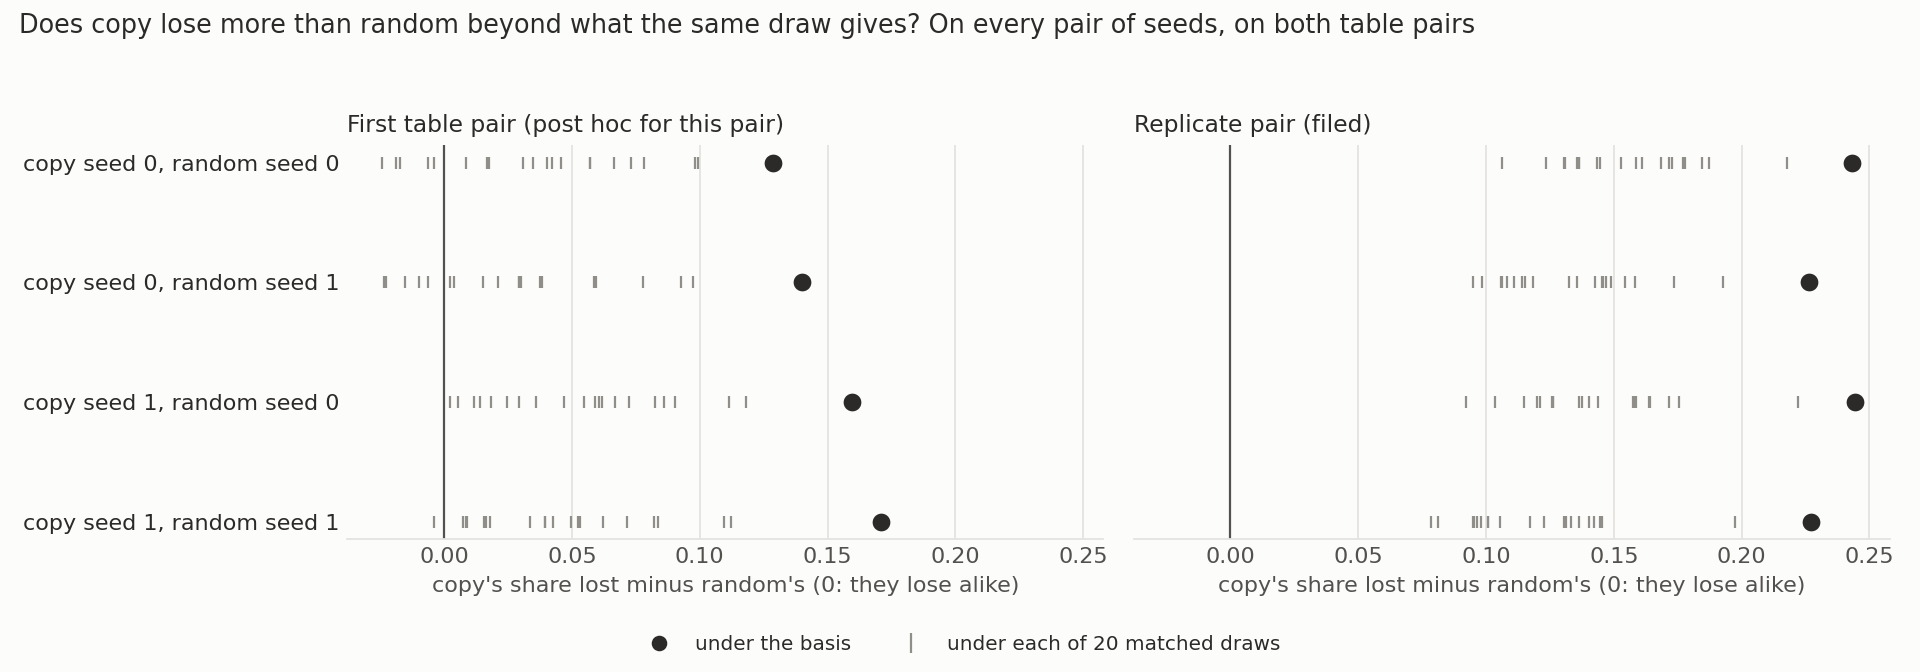

In [5]:
display(Image(FIG / "paired.png", width=1000))


**Reading it.** Yes, on all four seed pairs of both table pairs. Each dot is copy's share minus random's under the basis, and each tick is that same gap under one random removal. The replicate is the filed test, and its gaps read 0.23 to 0.24 against largest draws of 0.19 to 0.22. So this is no accident of one table pair.

The larger share gap on the replicate does not mean a stronger effect. The replicate's random map gained 20.7 log-odds against 13 to 14 on the first pair, so its share has a bigger denominator. Its update is also twice the norm. It learned the table almost fully, with geometric-mean probability near 0.99 where the first pair's reached 0.15 to 0.31. In net log-odds the gap is smaller on the replicate, at most 1.9 where the first pair reaches 2.7. Unfiled reads in net log-odds and in nats also clear all the draws on all eight pairs, narrowly on two.


### Post hoc, unfiled: does where the weights moved line up with what a state loses?


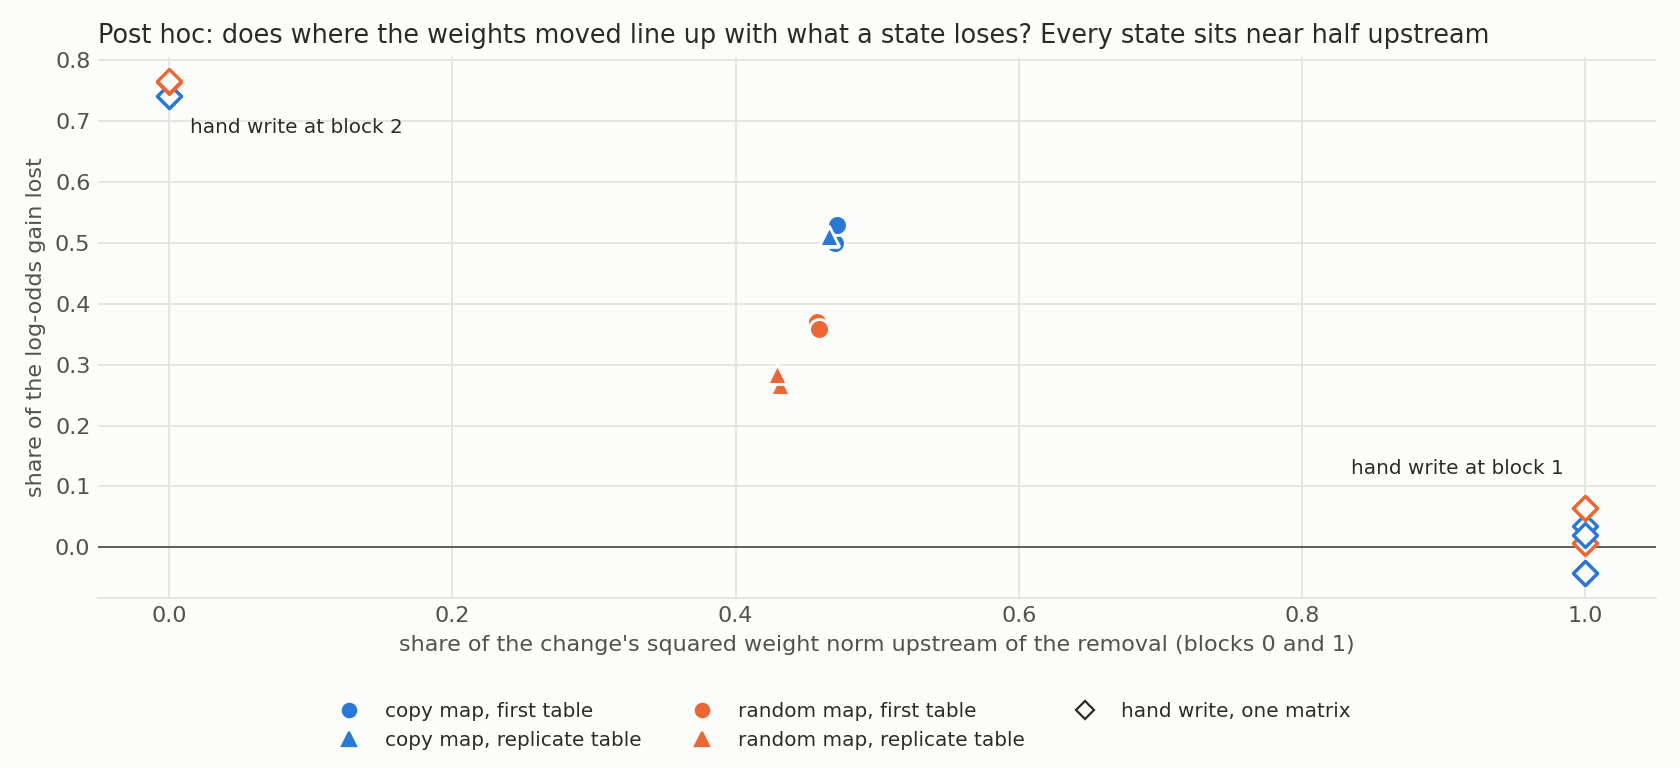

In [6]:
display(Image(FIG / "update_blocks.png", width=900))


**Reading it.** Not in the way a placement account needs, and this cannot settle it. A fine-tune changes all four blocks, and a part upstream of the removal could be spared as the block-1 write is. So a state's share might reflect where its update sits. We can read the split from the saved updates, by squared weight norm. Every state has 0.43 to 0.47 of its change upstream. Random has slightly less upstream than copy on both tables, so a spared upstream part would make random lose more, and it loses less.

This is weight norm, not function. Every block holds the same number of parameters, so a near-even split may say little. How much gain each block's change carries needs a forward pass with part of the update switched off, which this run did not do. We name no cause.


## What we learned

For `GOALS.md`'s question of new against existing capabilities, this narrows what token identity's removal can say. A mechanism built by hand to need only the token goes above its own band. So "above the band" here is not shown to mean more than needing the input token.

Copy over random repeats on independent keys, so something differs between the maps that a need they share does not explain. That difference can be read two ways. Copy may depend on more, or random may be spared more: random is the one further from the write than matched directions give. The run does not choose.

It does not follow that the copy map reuses an old mechanism, or that the random map built a new one. Nor does needing the token cap what a state can lose, since one write of one kind sets no ceiling. A circuit built from old parts reads as reuse throughout.

## How compelling is the evidence

The write's loss is strong for what it shows: the same matrix one block earlier loses about nothing. Its size is weaker, because the write answers less sharply than the states on copy, and its pseudo-inverse may amplify small changes. The replicate has two table pairs on one task format and one model, with 97 windows and two seeds per map. Its control is narrow. The draws share most of their directions with the basis, so "within" and "inside the draws" mean not shown specific, never shown not specific. All of this is at block 1 only, in log-odds as filed.

## Surprises

- **Filed sentence backwards.** The outcome sentence says a state loses more than the write, and the numbers say less. See above. The filing is not edited.
- **The lean on the write missed.** We leaned to "token needed, no more", and copy landed inside the draws. Had the filing counted a negative gap inside the draws as "the write loses at least as much", the outcome would have read that way. It did not, and the outcome stays "no call".
- **The two random tables differ.** The replicate's random map learned far more fully than the first pair's, with twice the update norm.
- **The replicate's control was a near thing.** It passed, with one draw above it.

## What next

1. **Split each update by block and read it through the removal.** One `debug` job, free, needing a GPU. Each state runs with only its early blocks changed, then only its late blocks. If the two parts' gains and shares differ between the maps by enough to account for the gap, placement becomes a candidate with a number behind it. If not, placement in this form is out.
2. **A second kind of key reader,** such as one written at block 3 or by attention. If it loses far less than this write, the 0.74 to 0.77 belongs to the pseudo-inverse rather than to needing the token.
3. **Wording.** On this format, say "needs the input token after block 1" in place of "reuses token identity", unless a located mechanism supports more. The user decides that in the definition batch.


## Scorecard

| id | Claim in words | Rule | Read | Verdict |
|---|---|---|---|---|
| Teeth, A | Original model loses more under the basis than the draws | drop over band | 2.863 against 2.580 | passes, reproduced |
| Teeth, B | The same on table B's keys | drop over band | 2.858 against 2.842 | passes, narrow |
| Placement | Removal between the two writes | block 1 input unmoved, block 2 moved, key earlier nowhere | 0, 0.892, 0 of 97 | passes |
| Write works | The block-2 write learned its table | gain over rotated floor | 13.1-14.1 against -5.0 to -0.8 | passes, all four |
| Write bites | The removal hits the write | share over its own band | 0.74-0.77 against 0.62-0.67 | yes |
| Read 1 | State minus write against the draws | filed first-match table | copy inside, random below, 2 of 4 pairs | no call; filed sentence reads backwards |
| Read 2 | Replicate repeats | filed band and paired test | 0.51, 0.51 over 0.427; 0.27, 0.28 under; 4 of 4 pairs | repeats |
| Own bands, B | Printed, decides nothing | each seed's band | copy above, random above | beside only |
| Lean, read 1 | "Token needed, no more" | not a bar | no call | missed |
| Lean, read 2 | Copy above, random within, every pair | not a bar | as leaned | held |

## Departures from the literature

None new. The definition and removal are E90's, and its report lists how they depart from Jain et al. 2024.

## Not run

- How much gain each block's change carries: the saved split is weight norm only, and the forward pass needs a GPU.
- A second kind of key reader, at another block or by attention.
- A resampling of the 97 windows, though the per-window reads are saved.
- A fuller variance match, the other blocks, the 24-key copy map under the block-2 write, new seeds.
- An independent check.

## Provenance

Job 52507, one L40, `debug` QoS, 2 min 15 s, $0. Results `experiments/token_identity/results/run.json`, filing `predictions.json`, unfiled reads `post_hoc.json`, per-window reads `results/large/reads_*.pt`. Report `reports/analyses/2026-11-05_analysis_e95-token-identity.md`.
